In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)


# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Make the time series data stationary using rolling mean and standard deviation
rolling_window = 24  # 24-hour window for hourly data
df['Parkings_rolling_mean'] = df['Parkings'].rolling(window=rolling_window).mean()
df['Parkings_rolling_std'] = df['Parkings'].rolling(window=rolling_window).std()
df['Parkings_stationary'] = (df['Parkings'] - df['Parkings_rolling_mean']) / df['Parkings_rolling_std']

# Drop NaN values resulting from rolling calculations
df.dropna(inplace=True)

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Perform auto_arima to find the best model parameters
auto_arima_model = auto_arima(train_data['Parkings_stationary'], 
                              exogenous=train_exog, 
                              seasonal=True, 
                              stationary=True,
                              m=24,  # Daily seasonality in hourly data
                              trace=True,
                              error_action='ignore', 
                              suppress_warnings=True,
                              stepwise=True,
                              max_order=None)

# Fit the best model found by auto_arima on the training data
auto_arima_model.fit(train_data['Parkings_stationary'], exogenous=train_exog)

# Predict using the fitted model with exogenous features
predictions_stationary = auto_arima_model.predict(n_periods=len(test_data), exogenous=test_exog)

# Invert the transformations to return to the original scale
predictions_rolling_mean_reversed = predictions_stationary * test_data['Parkings_rolling_std'] + test_data['Parkings_rolling_mean']

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions_rolling_mean_reversed, label='Predicted', color='red')
plt.legend()
plt.show()


Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[24] intercept   : AIC=inf, Time=8.81 sec
 ARIMA(0,0,0)(0,0,0)[24] intercept   : AIC=5914.305, Time=0.02 sec
 ARIMA(1,0,0)(1,0,0)[24] intercept   : AIC=1393.071, Time=2.04 sec
 ARIMA(0,0,1)(0,0,1)[24] intercept   : AIC=3225.032, Time=2.00 sec
 ARIMA(0,0,0)(0,0,0)[24]             : AIC=5914.846, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[24] intercept   : AIC=1927.941, Time=0.11 sec
 ARIMA(1,0,0)(2,0,0)[24] intercept   : AIC=1275.872, Time=10.23 sec
 ARIMA(1,0,0)(2,0,1)[24] intercept   : AIC=inf, Time=25.32 sec
 ARIMA(1,0,0)(1,0,1)[24] intercept   : AIC=inf, Time=5.59 sec
 ARIMA(0,0,0)(2,0,0)[24] intercept   : AIC=4970.691, Time=4.01 sec
 ARIMA(2,0,0)(2,0,0)[24] intercept   : AIC=540.503, Time=13.93 sec
 ARIMA(2,0,0)(1,0,0)[24] intercept   : AIC=624.586, Time=2.25 sec
 ARIMA(2,0,0)(2,0,1)[24] intercept   : AIC=inf, Time=27.95 sec
 ARIMA(2,0,0)(1,0,1)[24] intercept   : AIC=inf, Time=7.03 sec
 ARIMA(3,0,0)(2,0,0)[24] intercept   : AIC

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[24]             : AIC=inf, Time=40.45 sec
 ARIMA(0,1,0)(0,1,0)[24]             : AIC=23322.729, Time=0.09 sec
 ARIMA(1,1,0)(1,1,0)[24]             : AIC=22637.067, Time=1.96 sec
 ARIMA(0,1,1)(0,1,1)[24]             : AIC=inf, Time=9.55 sec
 ARIMA(1,1,0)(0,1,0)[24]             : AIC=22722.227, Time=0.13 sec
 ARIMA(1,1,0)(2,1,0)[24]             : AIC=22531.543, Time=5.08 sec
 ARIMA(1,1,0)(2,1,1)[24]             : AIC=inf, Time=28.16 sec
 ARIMA(1,1,0)(1,1,1)[24]             : AIC=inf, Time=7.43 sec
 ARIMA(0,1,0)(2,1,0)[24]             : AIC=23128.009, Time=3.89 sec
 ARIMA(2,1,0)(2,1,0)[24]             : AIC=22421.746, Time=6.98 sec
 ARIMA(2,1,0)(1,1,0)[24]             : AIC=22528.051, Time=2.30 sec
 ARIMA(2,1,0)(2,1,1)[24]             : AIC=inf, Time=39.45 sec
 ARIMA(2,1,0)(1,1,1)[24]             : AIC=inf, Time=10.49 sec
 ARIMA(3,1,0)(2,1,0)[24]             : AIC=22423.433, Time=7.59 sec
 ARIMA(2,1,1)(2,1,0)[24]             

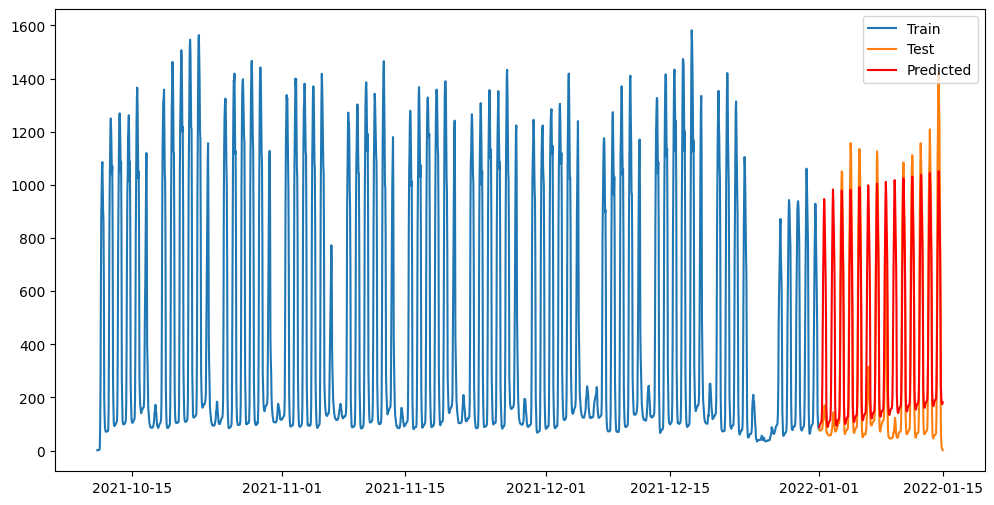

In [1]:
#non sationary
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from datetime import datetime

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_1_hour.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Convert exogenous features to appropriate data types
df['day_of_year'] = df['day_of_year'].astype(int)
df['weekday'] = df['weekday'].astype(int)
df['hour'] = df['hour'].astype(int)
df['is_holiday'] = df['is_holiday'].astype(int)

exogenous_features = ["day_of_year", "weekday", "hour", "is_holiday"]

# Split the data into training and test sets
end_date = datetime(2022, 1, 1)
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Ensure the training data index has a frequency set
train_data.index = pd.DatetimeIndex(train_data.index.values, freq='h')  # 'h' stands for hourly frequency

# Extract exogenous features for training and test sets
train_exog = train_data[exogenous_features]
test_exog = test_data[exogenous_features]

# Perform auto_arima to find the best model parameters
auto_arima_model = auto_arima(train_data['Parkings'], 
                              exogenous=train_exog, 
                              stationary=False,
                              seasonal=True, 
                              d=1, 
                              D=1,
                              m=24,  # Daily seasonality in hourly data
                              trace=True,
                              error_action='ignore', 
                              suppress_warnings=True,
                              stepwise=True)

# Fit the best model found by auto_arima on the training data
auto_arima_model.fit(train_data['Parkings'], exogenous=train_exog)

# Predict using the fitted model with exogenous features
predictions = auto_arima_model.predict(n_periods=len(test_data), exogenous=test_exog)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, predictions, label='Predicted', color='red')
plt.legend()
plt.show()